# LM30 Lab — Estimation Error and Robust Portfolios

Companion notebook to **From Calculus to Kelly, LM30**. It rebuilds the module's exhibits and computational examples from the daily total returns of five Taiwan-listed funds (E5) and the TWSE sector indices (U28). It solves the computational practice problems and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: E5's estimation and wealth frames, $T$, $A$, $A_{\mathrm w}$, the first window; U28 and its halves |
| 2 | Experiment 1 (Example 1, Example 2, Exhibit 2, the sign flips, R1's risk shares) and experiment 2 (Example 3, Exhibit 3) |
| 3 | Ledoit–Wolf by hand and with scikit-learn (Example 4), (30.1)'s spectrum and $\kappa_c$ (Exhibit 4), 1/N at $c=0$ |
| 4 | U28's windows (Exhibit 5, Example 5), the pseudoinverse at $T=20$, experiment 3 |
| 5 | R5 re-implemented and checked against the through case's targets (Exhibit 6, Example 6); R1's, R3's and R5's realized volatility |
| 6 | (30.4) on U28's first half with cvxpy's dual values (Example 7) |
| 7 | Black–Litterman (Example 8, Exhibit 7, the knowledge check of Section 6) |
| 8 | Experiment 4 and its stationary-bootstrap variant; the single-index matrix (Exhibit 8); the repairs of $C_{\text{pw}}$ (Example 9) |
| 9 | Practice problems 10, 11 and 12 |
| 10 | Extension: LM7's monthly re-estimation question, with shrinkage |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds six files, and the notebook reads nothing outside `data/`:

- `e5_estimation.csv`: E5's estimation frame, one row per date and fund (`base`, `date`, `fund`, `R`): the 2,362 dates on which all five funds have a one-session total return, from 18 January 2017 to 8 October 2026.
- `e5_wealth.csv`: E5's wealth frame (the same columns and `traded`): every session from 18 January 2017, a halted fund earning 0.
- `rule_targets.csv`: the through case's target exposures of R1–R8 at each of the 92 signals, with the trade date, turnover and cost (`data/vol5_rules.py`).
- `rule_wealth.csv`: each rule's net and gross wealth after each session's trade, from the first trade.
- `sectors_close_raw.csv` and `sectors_close_repairs.csv`: the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the TWSE sector indices, and the closes it copied from another date or series with their 13:30:00 values (`TaiwanStockEvery5SecondsIndex`, a paid dataset), as in LM23's lab.

**Conventions (as in the module).**

- Simple daily returns; every covariance matrix divides by $T$ (`ddof=0`, passed explicitly). Annual inputs are $A$ times the daily ones with the sample's own $A$: E5's $A=T/\text{years}$ from the base close of 17 January 2017; U28's $A=245.4794$.
- Excess returns over $r_f=1.5\%$ a year, $r_f/A$ a day. Years of sessions are $\tau=T/A$.
- Shrinkage (30.1): $\hat\Sigma_c=c\hat\Sigma+(1-c)\bar\lambda I$, $\bar\lambda=\operatorname{tr}\hat\Sigma/N$; scikit-learn's `shrinkage_` is $1-\hat c$.
- Long-only minimum variance and maximum Sharpe ratio are solved exactly, as a non-negative least-squares problem through the Cholesky factor (the through case's method); a weight below $10^{-6}$ is 0.
- Simulations create `np.random.default_rng([e, 20261011])` once per experiment $e$. A Monte Carlo result prints at its standard error's first significant digit; a median's or an SD's standard error comes from 20 batches of 500 samples.
- Medians use `method="inverted_cdf"`; counts against a threshold use the guard `1e-12`.
- The first window and every simulation's model are *In-sample* estimates; experiments 1–3 are *Model*; the through case's rules from March 2019 and U28's second half are *Out-of-sample*.

In [1]:
import math
import time
from datetime import date
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from arch.bootstrap import optimal_block_length
from scipy.linalg import cholesky, solve_triangular
from scipy.optimize import nnls
from scipy.stats import kurtosis
from sklearn.covariance import LedoitWolf

DATA = Path("data")
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
SEED = 20261011
RF = 0.015
WINDOW = 504
EPS = 1e-12
ZERO = 1e-6
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FULL_DATA = True                     # set in Part 1: False when U28's repaired closes are missing (free plan)


def show(label, value, fmt, printed, u28=False):
    # print a value next to the module's printed value; assert that they agree (U28's only with the full data)
    got = format(value, fmt)
    ok = got == printed
    note = "" if ok else ("   (differs: U28 closes were dropped)" if u28 and not FULL_DATA else "   MISMATCH")
    print(f"{label}: {got}   [book: {printed}]{note}")
    if not (u28 and not FULL_DATA):
        assert ok, (label, got, printed)


def k_of(se):
    # decimals at which a Monte Carlo result prints: the SE's first significant digit
    return -math.floor(math.log10(float(f"{se:.0e}")))


def show_mc(label, x, se, printed, printed_se, u28=False):
    k = k_of(se)
    show(label, x, f".{k}f", printed, u28)
    show(label + " (SE)", se, f".{k}f", printed_se, u28)


def cov0(x):
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]                    # divisor T, as np.cov(x, rowvar=False, ddof=0)


def gmv(S):
    w = np.linalg.solve(S, np.ones(S.shape[0]))
    return w / w.sum()


def vol(w, S, a):
    return math.sqrt(a * float(w @ S @ w))


def fro2(M):
    return float(np.sum(M * M))


def c_lw(x):
    return 1 - float(LedoitWolf(assume_centered=False).fit(x).shrinkage_)


def shrunk(x):
    return np.asarray(LedoitWolf(assume_centered=False).fit(x).covariance_, dtype=float)


def normal_noise(S, T):
    # (18.4): E|S_hat - S|_F^2 for T iid normal vectors with a known mean
    return (fro2(S) + float(np.trace(S)) ** 2) / T


def qp_simplex(S, a):
    # min y'Sy subject to a'y = 1, y >= 0, exactly: min 1/2 z'Sz - a'z, z >= 0, as NNLS |Rz - R^-T a| (S = R'R)
    if a.max() <= 0:
        return None
    R = cholesky(S, lower=False)
    z, _ = nnls(R, solve_triangular(R, a, trans="T"), maxiter=1000)
    y = z / float(a @ z)
    nu = 2 * S @ y - (2 / float(a @ z)) * a       # multipliers of y >= 0: zero where y > 0, nonnegative elsewhere
    assert nu.min() > -1e-9 * abs(2 / float(a @ z)) * float(np.abs(a).max())
    return y


def minvar(S):
    y = qp_simplex(S, np.ones(S.shape[0]))
    return y / y.sum()


def maxsharpe(S, e):
    y = qp_simplex(S, e)
    return None if y is None else y / y.sum()


def mean_se(v):
    v = np.asarray(v, dtype=float)
    return float(v.mean()), float(v.std() / math.sqrt(len(v)))


def batch_se(stat, data, nb=20):
    vals = np.array([np.asarray(stat(chunk), dtype=float) for chunk in np.array_split(data, nb)])
    return np.atleast_1d(vals.std(axis=0) / math.sqrt(nb))


def q50(v):
    return float(np.quantile(v, 0.5, method="inverted_cdf"))


def fd(args):
    # a fund -> rounded value dict for printing: fd((values, decimals))
    v, k = (args if isinstance(args, tuple) else (args, 0))
    return {f: round(float(x), k) for f, x in zip(FUNDS, v)}

## Part 1 — Data

E5's two frames come in long format. The estimation frame holds the dates on which every fund has a one-session total return; the wealth frame holds every session, with a flag for the funds that traded. $A$ is the estimation frame's returns per calendar year from the base close; $A_{\mathrm w}$ the wealth frame's.

In [2]:
str_cols = {"fund": pl.Utf8, "base": pl.Utf8, "date": pl.Utf8}
est = pl.read_csv(DATA / "e5_estimation.csv", schema_overrides=str_cols)
wide = est.pivot(on="fund", index="date", values="R").sort("date")
assert wide.select(FUNDS).null_count().sum_horizontal()[0] == 0
est_dates = wide["date"].to_list()
X5 = wide.select(FUNDS).to_numpy()
base = est["base"][0]
years = (date.fromisoformat(est_dates[-1]) - date.fromisoformat(base)).days / 365.25
A = len(est_dates) / years
wfr = pl.read_csv(DATA / "e5_wealth.csv", schema_overrides=str_cols)
wealth_dates = sorted(set(wfr["date"].to_list()))
A_w = len(wealth_dates) / years
print(f"estimation frame: T {len(est_dates)} ({est_dates[0]} .. {est_dates[-1]}), A {A:.6f}")
print(f"wealth frame: {len(wealth_dates)} sessions, A_w {A_w:.6f}")
show("A", A, ".2f", "242.95")
show("A_w", A_w, ".2f", "243.57")

rows0 = sum(1 for d in est_dates if d <= "2019-02-27")       # the first signal
x0 = X5[rows0 - WINDOW:rows0]
print("first window:", est_dates[rows0 - WINDOW], "..", est_dates[rows0 - 1], f"({len(x0)} returns)")
mu_d, S_d = x0.mean(axis=0), cov0(x0)
mu_a, S_a = A * mu_d, A * S_d
sd_a = np.sqrt(np.diag(S_a))
e_d = mu_d - RF / A
Si = np.linalg.inv(S_d)
delta = float(np.ones(5) @ Si @ e_d)
w_tan = Si @ e_d / delta
sr_star = math.sqrt(A * float(e_d @ Si @ e_d))
w1 = np.full(5, 0.2)


def sr_true(f):
    # the model's annual Sharpe ratio of exposures f (Section 2)
    return math.sqrt(A) * float(f @ e_d) / math.sqrt(float(f @ S_d @ f))


sr_1n = sr_true(w1)
print("tangency weights (%):", np.round(100 * w_tan, 1), "sum of rounded:", round(sum(np.round(100 * w_tan, 1)), 1))
show("delta", delta, ".2f", "11.27")
show("SR*", sr_star, ".3f", "0.880")
show("SR(1/N)", sr_1n, ".3f", "0.327")

estimation frame: T 2362 (2017-01-18 .. 2026-10-08), A 242.951422
wealth frame: 2368 sessions, A_w 243.568572
A: 242.95   [book: 242.95]
A_w: 243.57   [book: 243.57]
first window: 2017-02-13 .. 2019-02-27 (504 returns)
tangency weights (%): [ 11.8  62.6  37.8   2.6 -14.7] sum of rounded: 100.1
delta: 11.27   [book: 11.27]
SR*: 0.880   [book: 0.880]
SR(1/N): 0.327   [book: 0.327]


U28 follows LM23's lab. Every close listed in `sectors_close_repairs.csv` is replaced by its 13:30:00 value. On FinMind's free plan those values are missing, and the cell drops the listed closes instead, never estimating them; the U28 results then differ from the book's, and the checks say so.

In [3]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
series = [c for c in raw.columns if c != "date"]
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
n_listed, n_replaced = rep.height, int(rep["close_1330"].is_not_null().sum())
FULL_DATA = n_replaced == n_listed
U28 = [c for c in series if c not in ("TAIEX", *AGGREGATES)]
closes = fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
keep = ["TAIEX", *U28]
ret = (closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in keep])
             .slice(1)
             .filter(pl.all_horizontal([pl.col(c).is_not_null() for c in keep])))
XU = ret.select(U28).to_numpy()
MKT = ret["TAIEX"].to_numpy()
u_dates = ret["date"].to_list()
AU = len(u_dates) / ((date.fromisoformat(LAST_CLOSE) - date.fromisoformat(FIRST_CLOSE)).days / 365.25)
H = len(u_dates) // 2
X1, X2 = XU[:H], XU[H:]
S1, S2 = cov0(X1), cov0(X2)
NU = len(U28)
print(f"listed closes {n_listed}: replaced {n_replaced}; full data: {FULL_DATA}")
print(f"U28: {NU} sectors, T {len(u_dates)} ({u_dates[0]} .. {u_dates[-1]}), A {AU:.4f}; halves of {H}")
print("first half to", u_dates[H - 1], "| second half from", u_dates[H])
show("U28 A", AU, ".4f", "245.4794", u28=True)
show("halves", H, ",d", "2,191", u28=True)

listed closes 561: replaced 561; full data: True
U28: 28 sectors, T 4382 (2008-12-02 .. 2026-10-08), A 245.4794; halves of 2191
first half to 2017-10-06 | second half from 2017-10-11
U28 A: 245.4794   [book: 245.4794]
halves: 2,191   [book: 2,191]


## Part 2 — How far plug-in weights fall from the truth

Experiment 1 takes the first window's mean and matrix as the truth and draws 10,000 samples of 504 days, one `standard_normal((504, 5))` call per sample, coloured by the Cholesky factor. Each sample gives three plug-in exposures at the model's fixed $\delta$, the plug-in minimum variance and R1's risk shares.

In [4]:
t0 = time.time()
Lc = np.linalg.cholesky(S_d)
rng1 = np.random.default_rng([1, SEED])
n1 = 10_000
sr_b, sr_m, sr_s = np.empty(n1), np.empty(n1), np.empty(n1)
fb_all, fs_all = np.empty((n1, 5)), np.empty((n1, 5))
mv_true, mv_pred = np.empty(n1), np.empty(n1)
rs_all = np.empty((n1, 5))
for i in range(n1):
    r = mu_d + rng1.standard_normal((WINDOW, 5)) @ Lc.T
    Sh = cov0(r)
    eh = r.mean(axis=0) - RF / A
    fb = np.linalg.solve(Sh, eh) / delta              # both estimated
    fm = Si @ eh / delta                              # means only
    fs = np.linalg.solve(Sh, e_d) / delta             # covariances only
    sr_b[i], sr_m[i], sr_s[i] = sr_true(fb), sr_true(fm), sr_true(fs)
    fb_all[i], fs_all[i] = fb, fs
    wm = gmv(Sh)
    mv_true[i], mv_pred[i] = vol(wm, S_d, A), vol(wm, Sh, A)
    g1 = Sh @ w1
    rs_all[i] = w1 * g1 / float(w1 @ g1)              # R1's risk shares, LM27's statistic
print(f"experiment 1: {time.time() - t0:.1f} s")
show_mc("mean SR, both", *mean_se(sr_b), "0.423", "0.003")
show_mc("mean SR, means only", *mean_se(sr_m), "0.425", "0.003")
show_mc("mean SR, covariances only", *mean_se(sr_s), "0.87686", "0.00002")
show_mc("median SR, both", q50(sr_b), float(batch_se(lambda c: q50(c[:, 0]), sr_b[:, None])[0]), "0.489", "0.004")
p_lose = float((sr_b < sr_1n - EPS).mean())
show_mc("1/N wins (%)", 100 * p_lose, 100 * math.sqrt(p_lose * (1 - p_lose) / n1), "31.4", "0.5")
nneg = int((fb_all.sum(axis=1) <= EPS).sum())
print(f"samples with 1'f_hat <= 0: {nneg} of {n1} ({100 * nneg / n1:.2f}%, exactly a tie at one decimal: print 21%)")
show("sign flips", nneg, ",d", "2,115")

experiment 1: 0.6 s
mean SR, both: 0.423   [book: 0.423]
mean SR, both (SE): 0.003   [book: 0.003]
mean SR, means only: 0.425   [book: 0.425]
mean SR, means only (SE): 0.003   [book: 0.003]
mean SR, covariances only: 0.87686   [book: 0.87686]
mean SR, covariances only (SE): 0.00002   [book: 0.00002]
median SR, both: 0.489   [book: 0.489]
median SR, both (SE): 0.004   [book: 0.004]
1/N wins (%): 31.4   [book: 31.4]
1/N wins (%) (SE): 0.5   [book: 0.5]
samples with 1'f_hat <= 0: 2115 of 10000 (21.15%, exactly a tie at one decimal: print 21%)
sign flips: 2,115   [book: 2,115]


0050: SD both 57.4829 (batch SE 0.4446), covariances only 3.30033 (batch SE 0.02405), ratio 17.417
00646: SD both 67.1105 (batch SE 0.5061), covariances only 4.73124 (batch SE 0.03296), ratio 14.185
00679B: SD both 80.7183 (batch SE 0.6485), covariances only 4.78526 (batch SE 0.03507), ratio 16.868
00635U: SD both 71.9797 (batch SE 0.4622), covariances only 3.98946 (batch SE 0.02737), ratio 18.042
00642U: SD both 28.8247 (batch SE 0.1791), covariances only 1.75402 (batch SE 0.01442), ratio 16.434
SD 00646 both: 67.1   [book: 67.1]
SD 00646 both (SE): 0.5   [book: 0.5]
SD 00646 covariances only: 4.73   [book: 4.73]
SD 00646 covariances only (SE): 0.03   [book: 0.03]
means-only SD of 00646, closed form: 65.7   [book: 65.7]
R1's true risk shares (%): [21.7 19.3  1.1  7.7 50.2] | SDs of the estimates (points): [1.331 1.147 1.031 1.074 1.67 ]
risk-share SD, 00679B: 1.031   [book: 1.031]
risk-share SD, 00679B (SE): 0.007   [book: 0.007]
risk-share SD, 00642U: 1.67   [book: 1.67]
risk-share S

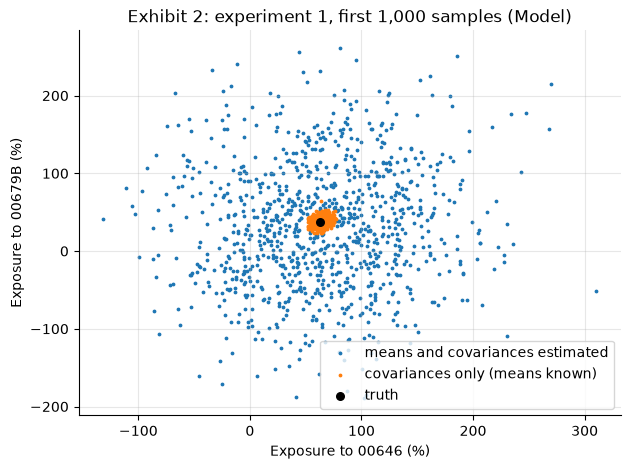

In [5]:
both = np.hstack([fb_all, fs_all])
sd = 100 * both.std(axis=0)
se_sd = 100 * batch_se(lambda c: c.std(axis=0), both)
for j, f in enumerate(FUNDS):
    print(f"{f}: SD both {sd[j]:.4f} (batch SE {se_sd[j]:.4f}), covariances only {sd[5 + j]:.5f} "
          f"(batch SE {se_sd[5 + j]:.5f}), ratio {sd[j] / sd[5 + j]:.3f}")
show_mc("SD 00646 both", sd[1], se_sd[1], "67.1", "0.5")
show_mc("SD 00646 covariances only", sd[6], se_sd[6], "4.73", "0.03")
sd_closed = 100 * np.sqrt(np.diag(Si) / WINDOW) / delta      # (28.9) and (16.4): Cov = Sigma^-1 / (delta^2 T)
show("means-only SD of 00646, closed form", sd_closed[1], ".1f", "65.7")
rs_true = w1 * (S_d @ w1) / float(w1 @ S_d @ w1)
rs_sd, rs_se = 100 * rs_all.std(axis=0), 100 * batch_se(lambda c: c.std(axis=0), rs_all)
print("R1's true risk shares (%):", np.round(100 * rs_true, 1), "| SDs of the estimates (points):", np.round(rs_sd, 3))
show_mc("risk-share SD, 00679B", rs_sd[2], rs_se[2], "1.031", "0.007")
show_mc("risk-share SD, 00642U", rs_sd[4], rs_se[4], "1.67", "0.01")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(100 * fb_all[:1000, 1], 100 * fb_all[:1000, 2], s=3, label="means and covariances estimated")
ax.scatter(100 * fs_all[:1000, 1], 100 * fs_all[:1000, 2], s=3, label="covariances only (means known)")
ax.scatter([100 * w_tan[1]], [100 * w_tan[2]], c="k", s=30, label="truth")
ax.set_xlabel("Exposure to 00646 (%)"); ax.set_ylabel("Exposure to 00679B (%)"); ax.legend()
ax.set_title("Exhibit 2: experiment 1, first 1,000 samples (Model)")
plt.show()

Example 2: by (20.2) the SE of an annual mean is $\sqrt A\,s/\sqrt\tau$; by (18.4) the root-mean-square error of $\hat\Sigma$ relative to $\lVert\Sigma\rVert_F$ is $\sqrt{(1+(\operatorname{tr}\Sigma)^2/\lVert\Sigma\rVert_F^2)/T}$. The plug-in minimum variance is predicted with $\hat\Sigma$ and judged with $\Sigma$.

In [6]:
tau = WINDOW / A
show("tau", tau, ".4f", "2.0745")
se_mean = 100 * sd_a / math.sqrt(tau)
print("SEs of the annual means (points):", np.round(se_mean, 1), "| means (%):", np.round(100 * mu_a, 1))
print("funds with |mean| below its SE:", int((np.abs(100 * mu_a) < se_mean - EPS).sum()))
rms = math.sqrt((1 + float(np.trace(S_d)) ** 2 / fro2(S_d)) / WINDOW)
show("RMS relative error of S_hat (%)", 100 * rms, ".1f", "8.5")
show_mc("plug-in minimum variance, predicted (%)", *mean_se(100 * mv_pred), "4.990", "0.002")
show_mc("plug-in minimum variance, true (%)", *mean_se(100 * mv_true), "5.0353", "0.0001")
show("sigma_min (%)", 100 * vol(gmv(S_d), S_d, A), ".2f", "5.02")

tau: 2.0745   [book: 2.0745]
SEs of the annual means (points): [ 9.4  8.2  5.9  6.5 16.1] | means (%): [ 7.5 10.   2.6  0.8 -1.4]
funds with |mean| below its SE: 4
RMS relative error of S_hat (%): 8.5   [book: 8.5]
plug-in minimum variance, predicted (%): 4.990   [book: 4.990]
plug-in minimum variance, predicted (%) (SE): 0.002   [book: 0.002]
plug-in minimum variance, true (%): 5.0353   [book: 5.0353]
plug-in minimum variance, true (%) (SE): 0.0001   [book: 0.0001]
sigma_min (%): 5.02   [book: 5.02]


Experiment 2 repeats the plug-in at seven lengths, 2,000 samples each, from one generator in increasing order (Example 3, Exhibit 3).

experiment 2: 2.1 s
T   126 ( 0.519 years of sessions): both 0.2298 (SE 0.0081); covariances only 0.865972 (SE 0.000228)
T   252 ( 1.037 years of sessions): both 0.3218 (SE 0.0077); covariances only 0.873227 (SE 0.000114)
T   504 ( 2.074 years of sessions): both 0.4225 (SE 0.0069); covariances only 0.876834 (SE 0.000054)
T  1008 ( 4.149 years of sessions): both 0.5459 (SE 0.0055); covariances only 0.878596 (SE 0.000028)
T  2016 ( 8.298 years of sessions): both 0.6721 (SE 0.0036); covariances only 0.879472 (SE 0.000014)
T  4032 (16.596 years of sessions): both 0.7594 (SE 0.0021); covariances only 0.879900 (SE 0.000007)
T  8064 (33.192 years of sessions): both 0.8156 (SE 0.0011); covariances only 0.880119 (SE 0.000003)
mean SR at 126: 0.230   [book: 0.230]
mean SR at 252: 0.322   [book: 0.322]
mean SR at 504: 0.422   [book: 0.422]
mean SR at 1008: 0.546   [book: 0.546]
mean SR at 2016: 0.672   [book: 0.672]
mean SR at 4032: 0.759   [book: 0.759]
mean SR at 8064: 0.816   [book: 0.816]
cov

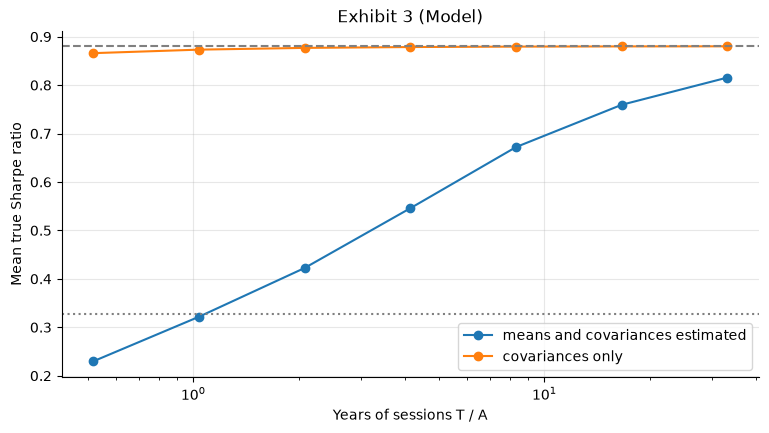

In [7]:
t0 = time.time()
rng2 = np.random.default_rng([2, SEED])
EXP2 = []
for T in [126, 252, 504, 1008, 2016, 4032, 8064]:
    vb, vs = np.empty(2000), np.empty(2000)
    for i in range(2000):
        r = mu_d + rng2.standard_normal((T, 5)) @ Lc.T
        Sh = cov0(r)
        vb[i] = sr_true(np.linalg.solve(Sh, r.mean(axis=0) - RF / A))
        vs[i] = sr_true(np.linalg.solve(Sh, e_d))
    EXP2.append((T, T / A, *mean_se(vb), *mean_se(vs)))
print(f"experiment 2: {time.time() - t0:.1f} s")
for T, y, m, s, mc, sc in EXP2:
    print(f"T {T:5d} ({y:6.3f} years of sessions): both {m:.4f} (SE {s:.4f}); covariances only {mc:.6f} (SE {sc:.6f})")
for (T, y, m, s, mc, sc), p in zip(EXP2, ["0.230", "0.322", "0.422", "0.546", "0.672", "0.759", "0.816"]):
    show(f"mean SR at {T}", m, ".3f", p)
show_mc("covariances only at 126", EXP2[0][4], EXP2[0][5], "0.8660", "0.0002")
fig, ax = plt.subplots()
ax.semilogx([e[1] for e in EXP2], [e[2] for e in EXP2], "o-", label="means and covariances estimated")
ax.semilogx([e[1] for e in EXP2], [e[4] for e in EXP2], "o-", label="covariances only")
ax.axhline(sr_star, ls="--", c="gray"); ax.axhline(sr_1n, ls=":", c="gray")
ax.set_xlabel("Years of sessions T / A"); ax.set_ylabel("Mean true Sharpe ratio"); ax.legend()
ax.set_title("Exhibit 3 (Model)")
plt.show()

## Part 3 — Ledoit–Wolf by hand and with scikit-learn

(30.3) on the first window, in annual units. The noise estimate's excess over (18.4)'s normal value is split by fund, entry by entry and by row (Example 4).

In [8]:
def lw_by_hand(x):
    T, n = x.shape
    xc = x - x.mean(axis=0)
    S = xc.T @ xc / T
    lam = float(np.trace(S)) / n
    d2 = fro2(S - lam * np.eye(n))
    b2 = sum(fro2(np.outer(v, v) - S) for v in xc) / T**2
    return lam, d2, b2, 1 - min(b2, d2) / d2


def noise_split(x):
    T, n = x.shape
    xc = x - x.mean(axis=0)
    S = xc.T @ xc / T
    noise = sum((np.outer(v, v) - S) ** 2 for v in xc) / T**2
    normal = (S**2 + np.outer(np.diag(S), np.diag(S))) / T
    ex = noise - normal
    d2 = fro2(S - float(np.trace(S)) / n * np.eye(n))
    return ex.sum(axis=1) / ex.sum(), 1 - min(float(normal.sum()), d2) / d2, float(noise.sum() / normal.sum())


lam0, d20, b20, c0 = lw_by_hand(math.sqrt(A) * x0)          # returns times sqrt(A): annual units
show("lam_bar", lam0, ".4f", "0.0204")
show("lam_bar as a volatility (%)", 100 * math.sqrt(lam0), ".1f", "14.3")
print(f"|S - lam I|^2 {d20:.4e}; noise estimate {b20:.4e}")
show("c_hat by hand", c0, ".4f", "0.9675")
sk = float(LedoitWolf(assume_centered=False).fit(x0).shrinkage_)
show("scikit-learn shrinkage_", sk, ".4f", "0.0325")
print(f"|c_hat - (1 - shrinkage_)| = {abs(c0 - (1 - sk)):.1e} (daily against annual inputs)")
dist0 = fro2(S_d - np.trace(S_d) / 5 * np.eye(5))              # (30.2) with the window's S as the truth
show("normal-model oracle", dist0 / (dist0 + normal_noise(S_d, WINDOW)), ".4f", "0.9851")
share0, _, ratio0 = noise_split(x0)
show("noise estimate / normal value", ratio0, ".2f", "2.14")
k0 = kurtosis(x0, axis=0, fisher=False, bias=True)
print("raw kurtosis:", fd((k0, 1)), "| share of the excess (%):", fd((100 * share0, 0)))

lam_bar: 0.0204   [book: 0.0204]
lam_bar as a volatility (%): 14.3   [book: 14.3]
|S - lam I|^2 1.8851e-03; noise estimate 6.1235e-05
c_hat by hand: 0.9675   [book: 0.9675]
scikit-learn shrinkage_: 0.0325   [book: 0.0325]
|c_hat - (1 - shrinkage_)| = 0.0e+00 (daily against annual inputs)
normal-model oracle: 0.9851   [book: 0.9851]
noise estimate / normal value: 2.14   [book: 2.14]
raw kurtosis: {'0050': 13.3, '00646': 8.1, '00679B': 4.0, '00635U': 3.3, '00642U': 4.5} | share of the excess (%): {'0050': 36.0, '00646': 21.0, '00679B': 4.0, '00635U': 0.0, '00642U': 39.0}


(30.1) keeps the eigenvectors and moves the eigenvalues to $c\lambda_k+(1-c)\bar\lambda$ (Exhibit 4). At $c=0$ the minimum-variance portfolio is 1/N.

c_hat, last 60 returns: 0.874   [book: 0.874]
kappa, last 60: 438   [book: 438]
kappa_c, last 60: 68.1   [book: 68.1]
kappa, first half: 126.05   [book: 126.05]
weights at c = 0 equal 1/N: True


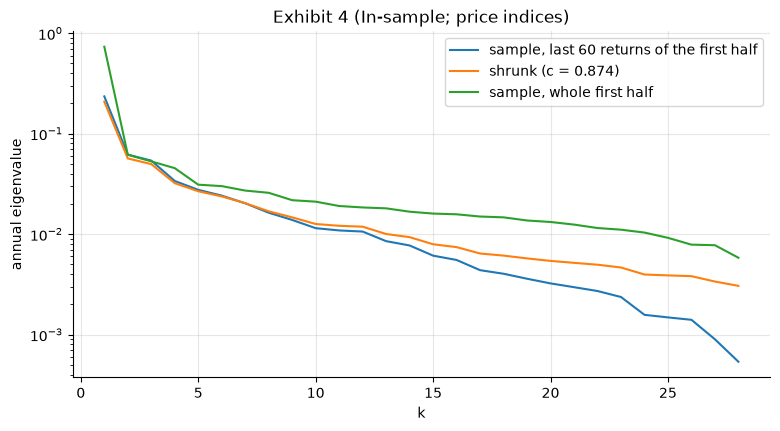

In [9]:
x60 = X1[-60:]
ev60 = np.sort(np.linalg.eigvalsh(AU * cov0(x60)))[::-1]
c60 = c_lw(x60)
evs60 = c60 * ev60 + (1 - c60) * ev60.mean()
evh = np.sort(np.linalg.eigvalsh(AU * S1))[::-1]
show("c_hat, last 60 returns", c60, ".3f", "0.874", u28=True)
show("kappa, last 60", ev60[0] / ev60[-1], ".0f", "438", u28=True)
show("kappa_c, last 60", evs60[0] / evs60[-1], ".1f", "68.1", u28=True)
show("kappa, first half", evh[0] / evh[-1], ".2f", "126.05", u28=True)
w_c0 = gmv(0.0 * S1 + np.trace(S1) / NU * np.eye(NU))
print("weights at c = 0 equal 1/N:", bool(np.abs(w_c0 - 1 / NU).max() < 1e-12))
k = np.arange(1, NU + 1)
fig, ax = plt.subplots()
ax.semilogy(k, ev60, label="sample, last 60 returns of the first half")
ax.semilogy(k, evs60, label=f"shrunk (c = {c60:.3f})")
ax.semilogy(k, evh, label="sample, whole first half")
ax.set_xlabel("k"); ax.set_ylabel("annual eigenvalue"); ax.legend(); ax.set_title("Exhibit 4 (In-sample; price indices)")
plt.show()

## Part 4 — U28's windows, the pseudoinverse and experiment 3

Each window is the last $T$ returns of the first half; each portfolio is judged on the second half (Exhibit 5, Example 5). At $T=20$ the sample matrix is singular: the part of $\mathbf 1$ in its null space, scaled to sum to 1, has zero predicted variance, and the pseudoinverse (12.7) gives the minimum within the column space.

In [10]:
rows5 = []
for T in (20, 30, 60, 120, 250, 504, 2191):
    x = X1[-T:]
    S = cov0(x)
    rk = int(np.linalg.matrix_rank(S))
    c = c_lw(x)
    ev = np.linalg.eigvalsh(S)
    lam = float(np.trace(S)) / NU
    kc = (c * ev[-1] + (1 - c) * lam) / (c * ev[0] + (1 - c) * lam)
    wl = gmv(shrunk(x))
    row = {"T": T, "rank": rk, "c_hat": round(c, 3), "kappa": None, "kappa_c": round(kc, 1), "predicted %": None,
           "realized %": None, "gross": None, "shrunk realized %": round(100 * vol(wl, S2, AU), 2)}
    if rk == NU:
        ws = gmv(S)
        row.update({"kappa": round(float(ev[-1] / ev[0])), "predicted %": round(100 * vol(ws, S, AU), 2),
                    "realized %": round(100 * vol(ws, S2, AU), 2), "gross": round(float(np.abs(ws).sum()), 2)})
    else:
        qn = np.linalg.eigh(S)[1][:, :NU - rk]
        p1 = qn @ (qn.T @ np.ones(NU))
        w0 = p1 / p1.sum()
        wp = np.linalg.pinv(S) @ np.ones(NU)
        wp /= wp.sum()
        print(f"T {T}: rank {rk}; 1 has {np.linalg.norm(p1) / math.sqrt(NU):.4f} of its length outside the column "
              f"space; that portfolio's predicted variance {float(w0 @ S @ w0):.1e} (zero to rounding)")
        print(f"   pseudoinverse: predicted {100 * vol(wp, S, AU):.2f}%, realized {100 * vol(wp, S2, AU):.2f}%")
    rows5.append(row)
tab5 = pl.DataFrame(rows5)
print(tab5)
show("T 30 realized (sample)", tab5.filter(pl.col("T") == 30)["realized %"][0], ".2f", "43.12", u28=True)
show("T 30 realized (shrunk)", tab5.filter(pl.col("T") == 30)["shrunk realized %"][0], ".2f", "12.46", u28=True)
show("T 60 realized (shrunk)", tab5.filter(pl.col("T") == 60)["shrunk realized %"][0], ".2f", "12.04", u28=True)

T 20: rank 19; 1 has 0.1809 of its length outside the column space; that portfolio's predicted variance 9.2e-21 (zero to rounding)
   pseudoinverse: predicted 1.78%, realized 17.03%
shape: (7, 9)
┌──────┬──────┬───────┬────────┬───┬─────────────┬────────────┬───────┬───────────────────┐
│ T    ┆ rank ┆ c_hat ┆ kappa  ┆ … ┆ predicted % ┆ realized % ┆ gross ┆ shrunk realized % │
│ ---  ┆ ---  ┆ ---   ┆ ---    ┆   ┆ ---         ┆ ---        ┆ ---   ┆ ---               │
│ i64  ┆ i64  ┆ f64   ┆ i64    ┆   ┆ f64         ┆ f64        ┆ f64   ┆ f64               │
╞══════╪══════╪═══════╪════════╪═══╪═════════════╪════════════╪═══════╪═══════════════════╡
│ 20   ┆ 19   ┆ 0.79  ┆ null   ┆ … ┆ null        ┆ null       ┆ null  ┆ 12.59             │
│ 30   ┆ 28   ┆ 0.823 ┆ 116097 ┆ … ┆ 1.34        ┆ 43.12      ┆ 13.48 ┆ 12.46             │
│ 60   ┆ 28   ┆ 0.874 ┆ 438    ┆ … ┆ 3.96        ┆ 13.85      ┆ 3.36  ┆ 12.04             │
│ 120  ┆ 28   ┆ 0.894 ┆ 127    ┆ … ┆ 4.49        ┆ 11.15      ┆ 2.05

Experiment 3 takes the first half's matrix as the truth (mean 0) and draws 1,000 samples at each length from one generator, one `standard_normal((T, 28))` call per sample. It judges the sample, shrunk and long-only portfolios by their true volatility, and pairs long-only against shrunk sample by sample. It takes about half a minute.

In [11]:
t0 = time.time()
L1 = np.linalg.cholesky(S1)
rng3 = np.random.default_rng([3, SEED])
EXP3 = {}
for T in (20, 30, 60, 120, 250, 504, 2191):
    vs, vl, vo, cc = [], [], [], []
    for _ in range(1000):
        x = rng3.standard_normal((T, NU)) @ L1.T
        S = cov0(x)
        lw = LedoitWolf(assume_centered=False).fit(x)
        cc.append(1 - float(lw.shrinkage_))
        vl.append(100 * vol(gmv(np.asarray(lw.covariance_, dtype=float)), S1, AU))
        if T > NU:
            vs.append(100 * vol(gmv(S), S1, AU))
            vo.append(100 * vol(minvar(AU * S), S1, AU))
    EXP3[T] = {"shrunk": mean_se(vl), "c": mean_se(cc)}
    if vs:
        EXP3[T].update({"sample": mean_se(vs), "longonly": mean_se(vo), "diff": mean_se(np.array(vo) - np.array(vl))})
print(f"experiment 3: {time.time() - t0:.1f} s")
for T, d in EXP3.items():
    print(T, {k: (round(v[0], 6), round(v[1], 6)) for k, v in d.items()})
show_mc("T 60 sample", *EXP3[60]["sample"], "15.51", "0.04", u28=True)
show_mc("T 60 shrunk", *EXP3[60]["shrunk"], "13.46", "0.02", u28=True)
show_mc("T 2191 sample", *EXP3[2191]["sample"], "11.4659", "0.0006", u28=True)
show_mc("T 2191 shrunk", *EXP3[2191]["shrunk"], "11.4651", "0.0006", u28=True)
show_mc("mean c_hat at 20", *EXP3[20]["c"], "0.810", "0.002", u28=True)
show_mc("mean c_hat at 2191", *EXP3[2191]["c"], "0.997963", "0.000002", u28=True)
show_mc("long-only minus shrunk at 2191", *EXP3[2191]["diff"], "1.2981", "0.0005", u28=True)

experiment 3: 4.2 s
20 {'shrunk': (14.663979, 0.029206), 'c': (0.809998, 0.001705)}
30 {'shrunk': (14.356639, 0.026851), 'c': (0.866901, 0.001009), 'sample': (47.117174, 0.974288), 'longonly': (13.971877, 0.023353), 'diff': (-0.384763, 0.025994)}
60 {'shrunk': (13.455696, 0.018647), 'c': (0.928076, 0.00044), 'sample': (15.506952, 0.042709), 'longonly': (13.400573, 0.012016), 'diff': (-0.055123, 0.017493)}
120 {'shrunk': (12.588435, 0.010653), 'c': (0.963542, 0.000166), 'sample': (12.963863, 0.01469), 'longonly': (13.07667, 0.005367), 'diff': (0.488236, 0.009837)}
250 {'shrunk': (11.996265, 0.005238), 'c': (0.982349, 5.5e-05), 'sample': (12.067093, 0.005851), 'longonly': (12.919542, 0.002794), 'diff': (0.923277, 0.004824)}
504 {'shrunk': (11.69538, 0.002643), 'c': (0.991193, 2e-05), 'sample': (11.711436, 0.002796), 'longonly': (12.835505, 0.001394), 'diff': (1.140125, 0.002428)}
2191 {'shrunk': (11.465111, 0.000602), 'c': (0.997963, 2e-06), 'sample': (11.465881, 0.000608), 'longonly': (

## Part 5 — R5 re-implemented, and the through case's volatility

R5 is R3 with the Ledoit–Wolf matrix: at each signal, the last 504 rows of the estimation frame through the signal, annual inputs, the exact long-only solver. The cell checks it, and R3, against `rule_targets.csv` at all 92 signals (Exhibit 6, Example 6). The realized volatilities come from `rule_wealth.csv`: daily net returns from the session after the first trade, times $\sqrt{A_{\mathrm w}}$.

92 signals, 2019-02-27 .. 2026-09-30; largest gap to the targets: R3 0.0e+00, R5 0.0e+00
first c_hat: 0.968   [book: 0.968]
median c_hat: 0.962   [book: 0.962]
lowest c_hat: 0.781   [book: 0.781]
lowest at 2026-03-31 | highest 0.979 at 2024-04-30 | below 0.9: 19 first 2020-03-31
largest R3-R5 gap (points): 13.1   [book: 13.1]
median gap (points): 1.6   [book: 1.6]
00642U kurtosis in that window: 48.9   [book: 48.9]
noise over normal there: 13.1   [book: 13.1]
c_hat with the normal value: 0.983   [book: 0.983]


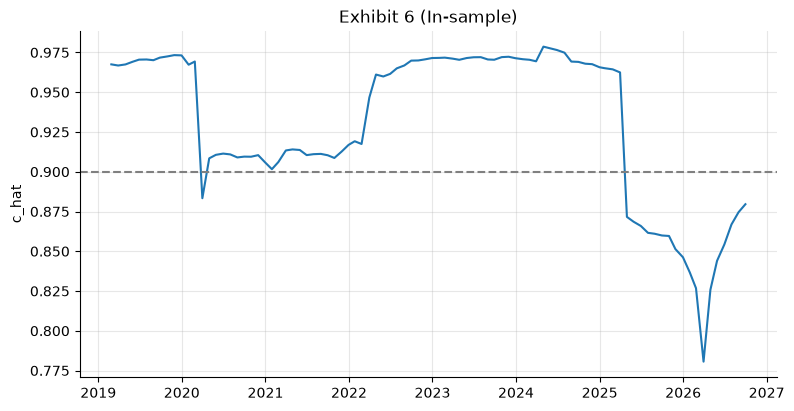

R1 realized volatility (%), 1851 returns: 12.48   [book: 12.48]
R3 realized volatility (%), 1851 returns: 9.96   [book: 9.96]
R5 realized volatility (%), 1851 returns: 9.97   [book: 9.97]


In [12]:
tg = pl.read_csv(DATA / "rule_targets.csv", schema_overrides={"signal": pl.Utf8, "trade": pl.Utf8})
sigs = tg.filter(pl.col("rule") == pl.lit("R5"))["signal"].to_list()
gap3 = gap5 = 0.0
chat, d35 = [], []
for sg in sigs:
    rows = sum(1 for d in est_dates if d <= sg)
    x = X5[rows - WINDOW:rows]
    w3 = minvar(A * cov0(x))
    w5 = minvar(A * shrunk(x))
    t3 = tg.filter((pl.col("rule") == pl.lit("R3")) & (pl.col("signal") == pl.lit(sg))).select(FUNDS).to_numpy()[0]
    t5 = tg.filter((pl.col("rule") == pl.lit("R5")) & (pl.col("signal") == pl.lit(sg))).select(FUNDS).to_numpy()[0]
    gap3, gap5 = max(gap3, float(np.abs(w3 - t3).max())), max(gap5, float(np.abs(w5 - t5).max()))
    chat.append(c_lw(x))
    d35.append(float(np.abs(t3 - t5).max()))
print(f"{len(sigs)} signals, {sigs[0]} .. {sigs[-1]}; largest gap to the targets: R3 {gap3:.1e}, R5 {gap5:.1e}")
assert gap3 < 1e-9 and gap5 < 1e-9
chat, d35 = np.array(chat), np.array(d35)
show("first c_hat", chat[0], ".3f", "0.968")
show("median c_hat", q50(chat), ".3f", "0.962")
show("lowest c_hat", chat.min(), ".3f", "0.781")
print("lowest at", sigs[int(np.argmin(chat))], "| highest", f"{chat.max():.3f}", "at", sigs[int(np.argmax(chat))],
      "| below 0.9:", int((chat < 0.9 - EPS).sum()), "first", sigs[int(np.argmax(chat < 0.9))])
show("largest R3-R5 gap (points)", 100 * d35.max(), ".1f", "13.1")
show("median gap (points)", 100 * q50(d35), ".1f", "1.6")
im = int(np.argmin(chat))
rows = sum(1 for d in est_dates if d <= sigs[im])
xm = X5[rows - WINDOW:rows]
share_m, c_norm, ratio_m = noise_split(xm)
km = kurtosis(xm, axis=0, fisher=False, bias=True)
show("00642U kurtosis in that window", km[4], ".1f", "48.9")
show("noise over normal there", ratio_m, ".1f", "13.1")
show("c_hat with the normal value", c_norm, ".3f", "0.983")
fig, ax = plt.subplots()
ax.plot([date.fromisoformat(s) for s in sigs], chat); ax.axhline(0.9, ls="--", c="gray")
ax.set_ylabel("c_hat"); ax.set_title("Exhibit 6 (In-sample)")
plt.show()

wealth = pl.read_csv(DATA / "rule_wealth.csv", schema_overrides={"date": pl.Utf8})
for rule, printed in (("R1", "12.48"), ("R3", "9.96"), ("R5", "9.97")):
    wv = wealth.filter(pl.col("rule") == pl.lit(rule)).sort("date")["wealth"].to_numpy()
    r = wv[1:] / wv[:-1] - 1
    show(f"{rule} realized volatility (%), {len(r)} returns", 100 * r.std() * math.sqrt(A_w), ".2f", printed)

## Part 6 — Constraints as implicit shrinkage, (30.4)

The long-only minimum variance on U28's first half, its multipliers in Jagannathan and Ma's scale ($\hat\Sigma\mathbf w=\nu_0\mathbf 1+\boldsymbol\nu$, half of LM29's), the adjusted matrix and cvxpy's dual values (Example 7).

In [13]:
w_lo = minvar(AU * S1)
act = w_lo > ZERO
g = S1 @ w_lo
nu0 = float(g[act].mean())
nu = np.where(act, 0.0, g - nu0)
S_nu = S1 - (np.outer(nu, np.ones(NU)) + np.outer(np.ones(NU), nu))
print("held:", [s for s, a in zip(U28, act) if a])
show("constraints binding", int((~act).sum()), "d", "19", u28=True)
print(f"S_nu's minimum-variance weights against the long-only ones: {np.abs(gmv(S_nu) - w_lo).max():.1e}")
show("smallest annual eigenvalue of S_nu", AU * np.linalg.eigvalsh(S_nu)[0], ".4f", "0.0059", u28=True)
red = 2 * nu / np.diag(S1)
print(f"largest variance reduction 2 nu_i / s_i^2: {100 * red.max():.1f}% ({U28[int(np.argmax(red))]})")
y = cp.Variable(NU)
cons = [cp.sum(y) == 1, y >= 0]
prob = cp.Problem(cp.Minimize(cp.quad_form(y, cp.psd_wrap(AU * S1))), cons)
prob.solve(solver=cp.CLARABEL, tol_gap_abs=1e-12, tol_gap_rel=1e-12, tol_feas=1e-12)
assert prob.status == "optimal"
nu_cv = np.asarray(cons[1].dual_value) / (2 * AU)
print(f"cvxpy: status {prob.status}; multipliers against nu: largest gap {np.abs(nu_cv - nu).max() / nu.max():.1e} of the largest")
w_s = gmv(S1)
show("sample realized (%)", 100 * vol(w_s, S2, AU), ".2f", "11.78", u28=True)
show("long-only realized (%)", 100 * vol(w_lo, S2, AU), ".2f", "12.14", u28=True)

held: ['BiotechnologyMedicalCare', 'CommunicationsInternet', 'Food', 'InformationService', 'IronSteel', 'OilGasElectricity', 'Other', 'PaperPulp', 'Tourism']
constraints binding: 19   [book: 19]
S_nu's minimum-variance weights against the long-only ones: 3.5e-16
smallest annual eigenvalue of S_nu: 0.0059   [book: 0.0059]
largest variance reduction 2 nu_i / s_i^2: 20.7% (Optoelectronic)
cvxpy: status optimal; multipliers against nu: largest gap 3.7e-10 of the largest
sample realized (%): 11.78   [book: 11.78]
long-only realized (%): 12.14   [book: 12.14]


## Part 7 — Black–Litterman

R2 is the reference (*constructed*), $\delta$ is calibrated to its window mean, and one view says that 00646 beats 0050 by the window's own difference (Example 8, Exhibit 7). The last lines check the knowledge check of Section 6: all five means as views with $\Xi=\hat\Sigma/T$.

R2 mean excess (%): 4.383   [book: 4.383]
R2 volatility (%): 6.709   [book: 6.709]
delta: 9.74   [book: 9.74]
implied excess returns (%): [7.79 5.14 0.46 1.02 3.71]
b (points): 2.491   [book: 2.491]
K e_eq (points): -2.649   [book: -2.649]
sqrt(K S K') (%): 12.264   [book: 12.264]
c 0.0: f_BL (%) [40. 20. 30. 10.  0.]
c 0.5: f_BL (%) [22.5 37.5 30.  10.   0. ]
c 1.0: f_BL (%) [ 4.9 55.1 30.  10.  -0. ]
plug-in (%): [ 13.6  72.4  43.8   3.  -17.1] total 115.8%
knowledge check: 0050 with all five views: 26.8   [book: 26.8]


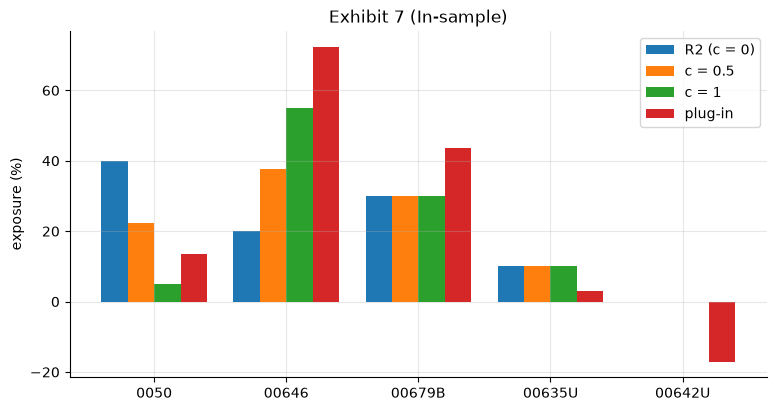

In [14]:
wref = np.array([0.40, 0.20, 0.30, 0.10, 0.0])
e_a = mu_a - RF
mex, vref = float(wref @ e_a), float(wref @ S_a @ wref)
dl = mex / vref
e_eq = dl * S_a @ wref
show("R2 mean excess (%)", 100 * mex, ".3f", "4.383")
show("R2 volatility (%)", 100 * math.sqrt(vref), ".3f", "6.709")
show("delta", dl, ".2f", "9.74")
print("implied excess returns (%):", np.round(100 * e_eq, 2))
K = np.array([-1.0, 1.0, 0, 0, 0])
b, kq, KSK = float(K @ e_a), float(K @ e_eq), float(K @ S_a @ K)
show("b (points)", 100 * b, ".3f", "2.491")
show("K e_eq (points)", 100 * kq, ".3f", "-2.649")
show("sqrt(K S K') (%)", 100 * math.sqrt(KSK), ".3f", "12.264")
fbl = {}
for c in (0.0, 0.5, 1.0):
    e_bl = e_eq + S_a @ K * c * (b - kq) / KSK                  # (30.5)
    fbl[c] = np.linalg.solve(S_a, e_bl) / dl
    assert np.abs(fbl[c] - (wref + K * c * (b - kq) / (dl * KSK))).max() < 1e-12
    print(f"c {c}: f_BL (%)", np.round(100 * fbl[c], 1))
fp = np.linalg.solve(S_a, e_a) / dl
print("plug-in (%):", np.round(100 * fp, 1), f"total {100 * fp.sum():.1f}%")
f_all = np.linalg.solve(S_a, 0.5 * e_a + 0.5 * e_eq) / dl          # K = I, Xi = S/T, c = 0.5
show("knowledge check: 0050 with all five views", 100 * f_all[0], ".1f", "26.8")
xpos = np.arange(5)
fig, ax = plt.subplots()
for j, (lab, v) in enumerate([("R2 (c = 0)", fbl[0.0]), ("c = 0.5", fbl[0.5]), ("c = 1", fbl[1.0]), ("plug-in", fp)]):
    ax.bar(xpos + 0.2 * j - 0.3, 100 * v, width=0.2, label=lab)
ax.set_xticks(xpos, FUNDS); ax.set_ylabel("exposure (%)"); ax.legend(); ax.set_title("Exhibit 7 (In-sample)")
plt.show()

## Part 8 — Resampling, the single-index matrix and the repairs of $C_{\text{pw}}$

Experiment 4 draws 1,000 iid bootstrap resamples of the first window's rows (LM22's iid bootstrap, `integers(0, 504, 504)` per resample) and averages R4's long-only maximum-Sharpe portfolio, with R3's minimum variance where no fund's mean exceeds $r_f$. The variant uses LM22's stationary bootstrap with its own generator, `default_rng([5, 20261011])`, 1,000 resamples in arch's draw order, and a block length by LM22's rule on the five funds' returns (the largest of the five stationary estimates on the squared demeaned returns, rounded).

In [15]:
def resampled(idx_fn, rng, B=1000):
    W, fallback = np.empty((B, 5)), 0
    for i in range(B):
        xb = x0[idx_fn(rng)]
        Sb = A * cov0(xb)
        wb = maxsharpe(Sb, A * xb.mean(axis=0) - RF)
        if wb is None:
            fallback += 1
            wb = minvar(Sb)
        W[i] = wb
    return W, fallback


def stationary_idx(rng, T, ell):
    # day indices of one stationary resample, drawn in arch's order (LM22)
    start = rng.integers(T, size=T)
    new = rng.random(T) <= 1 / ell
    new[0] = True
    first = np.flatnonzero(new)
    blk = np.cumsum(new) - 1
    step = np.arange(T) - first[blk]
    return (start[first][blk] + step) % T


W4, fb4 = resampled(lambda r: r.integers(0, WINDOW, WINDOW), np.random.default_rng([4, SEED]))
mw, sw = 100 * W4.mean(axis=0), 100 * W4.std(axis=0) / math.sqrt(1000)
pz = 100 * (W4 < ZERO).mean(axis=0)
print("experiment 4, mean weights (%):", fd((mw, 1)), "| fallback:", fb4)
print("share of resamples excluding each fund (%):", fd((pz, 0)))
show_mc("smallest mean weight", mw.min(), sw[int(np.argmin(mw))], "3.8", "0.4")
show_mc("largest mean weight", mw.max(), sw[int(np.argmax(mw))], "35.2", "0.9")
ell = round(float(optimal_block_length((x0 - x0.mean(axis=0)) ** 2)["stationary"].max()))
W5, fb5 = resampled(lambda r: stationary_idx(r, WINDOW, ell), np.random.default_rng([5, SEED]))
print(f"stationary variant (block length {ell}): mean weights (%)", fd((100 * W5.mean(axis=0), 1)),
      "| excluded (%):", fd((100 * (W5 < ZERO).mean(axis=0), 0)), "| fallback:", fb5)

experiment 4, mean weights (%): {'0050': 18.4, '00646': 35.2, '00679B': 29.1, '00635U': 13.5, '00642U': 3.8} | fallback: 12
share of resamples excluding each fund (%): {'0050': 42.0, '00646': 18.0, '00679B': 30.0, '00635U': 55.0, '00642U': 72.0}
smallest mean weight: 3.8   [book: 3.8]
smallest mean weight (SE): 0.4   [book: 0.4]
largest mean weight: 35.2   [book: 35.2]
largest mean weight (SE): 0.9   [book: 0.9]
stationary variant (block length 20): mean weights (%) {'0050': 14.8, '00646': 36.2, '00679B': 27.4, '00635U': 16.0, '00642U': 5.6} | excluded (%): {'0050': 42.0, '00646': 15.0, '00679B': 31.0, '00635U': 52.0, '00642U': 67.0} | fallback: 11


The single-index matrix keeps the market factor and drops the residual covariances (Exhibit 8); the five estimators are fitted on the first half and judged on the second. The last row chooses $c$ on the second half itself, *In-sample*.

In [16]:
m1 = MKT[:H] - MKT[:H].mean()
Xc = X1 - X1.mean(axis=0)
beta = Xc.T @ m1 / float(m1 @ m1)
res = Xc - np.outer(m1, beta)
SF = np.outer(beta, beta) * float(m1 @ m1) / H + np.diag((res**2).mean(axis=0))
Sc1 = shrunk(X1)
ests = {"Sample": (gmv(S1), S1), "Shrunk (Ledoit-Wolf)": (gmv(Sc1), Sc1), "Long-only": (w_lo, S1),
        "Single index": (gmv(SF), SF), "1/N": (np.full(NU, 1 / NU), S1)}
tab8 = pl.DataFrame([{"estimator": k, "predicted %": round(100 * vol(w, M, AU), 2), "realized %": round(100 * vol(w, S2, AU), 2)}
                     for k, (w, M) in ests.items()])
print(tab8)
grid = np.round(np.linspace(0, 1, 101), 2)
lam1 = float(np.trace(S1)) / NU
rv = [vol(gmv(c * S1 + (1 - c) * lam1 * np.eye(NU)), S2, AU) for c in grid]
print(f"best c in hindsight: {grid[int(np.argmin(rv))]:.2f} ({100 * min(rv):.2f}%)")
print(f"parameters: single index {2 * NU + 1}, sample {NU * (NU + 1) // 2}")
show("single index realized (%)", 100 * vol(gmv(SF), S2, AU), ".2f", "12.67", u28=True)

shape: (5, 3)
┌──────────────────────┬─────────────┬────────────┐
│ estimator            ┆ predicted % ┆ realized % │
│ ---                  ┆ ---         ┆ ---        │
│ str                  ┆ f64         ┆ f64        │
╞══════════════════════╪═════════════╪════════════╡
│ Sample               ┆ 11.4        ┆ 11.78      │
│ Shrunk (Ledoit-Wolf) ┆ 11.41       ┆ 11.78      │
│ Long-only            ┆ 12.74       ┆ 12.14      │
│ Single index         ┆ 11.01       ┆ 12.67      │
│ 1/N                  ┆ 15.98       ┆ 15.51      │
└──────────────────────┴─────────────┴────────────┘
best c in hindsight: 0.98 (11.78%)
parameters: single index 57, sample 406
single index realized (%): 12.67   [book: 12.67]


Example 9: LM10's constructed $C_{\text{pw}}$ from its printed entries, repaired by shrinkage toward $I$, by clipping, and by Higham's (2002b) alternating projections with Dykstra's correction, checked against cvxpy.

In [17]:
Cp = np.array([[1.0, 0.982, 0.199], [0.982, 1.0, -0.444], [0.199, -0.444, 1.0]])
evp, Qp = np.linalg.eigh(Cp)
print("eigenvalues:", np.round(evp[::-1], 4), f"det {np.linalg.det(Cp):.6f}")
cmax = 1 / (1 - evp[0])
Csh = cmax * Cp + (1 - cmax) * np.eye(3)
Ccl = Qp @ np.diag(np.clip(evp, 0, None)) @ Qp.T
Ccl = Ccl / np.outer(np.sqrt(np.diag(Ccl)), np.sqrt(np.diag(Ccl)))
Y, dS = Cp.copy(), np.zeros_like(Cp)
for it in range(100_000):                     # Higham's projections with Dykstra's correction
    Rm = Y - dS
    wv, Vv = np.linalg.eigh(Rm)
    Xp = Vv @ np.diag(np.clip(wv, 0, None)) @ Vv.T
    dS = Xp - Rm
    Yn = Xp.copy()
    np.fill_diagonal(Yn, 1.0)
    done = float(np.abs(Yn - Y).max()) < 1e-15
    Y = Yn
    if done:
        break
Xv = cp.Variable((3, 3), symmetric=True)
pc = cp.Problem(cp.Minimize(cp.sum_squares(Xv - Cp)), [Xv >> 0, cp.diag(Xv) == 1])
pc.solve(solver=cp.CLARABEL, tol_gap_abs=1e-10, tol_gap_rel=1e-10, tol_feas=1e-10)
off = [(0, 1), (0, 2), (1, 2)]
for name, M in (("shrunk", Csh), ("clipped", Ccl), ("nearest", Y)):
    print(f"{name}: off-diagonal {[round(float(M[i, j]), 3) for i, j in off]}, "
          f"Frobenius distance {math.sqrt(fro2(M - Cp)):.3f}")
show("c_max", cmax, ".4f", "0.8605")
print(f"cvxpy {pc.status}: largest gap to Higham's matrix {np.abs(np.asarray(Xv.value) - Y).max():.1e}")

eigenvalues: [ 2.0149  1.1471 -0.1621] det -0.374592
shrunk: off-diagonal [0.845, 0.171, -0.382], Frobenius distance 0.216
clipped: off-diagonal [0.852, 0.154, -0.385], Frobenius distance 0.211
nearest: off-diagonal [0.864, 0.139, -0.379], Frobenius distance 0.209
c_max: 0.8605   [book: 0.8605]
cvxpy optimal: largest gap to Higham's matrix 1.4e-07


## Part 9 — Practice problems 10, 11 and 12

**Problem 10** is Part 3: $\hat c=0.9675$ by hand and with scikit-learn, the normal oracle 0.9851 and the ratio 2.14. 0050 carries 36% of the excess and 00642U 39%.

**Problem 11** is Part 2: the three mean true Sharpe ratios, 1/N's 31.4% and the 2,115 sign flips. The first window meets two of DeMiguel, Garlappi and Uppal's conditions (a best Sharpe ratio well above 1/N's, few assets) but not the third (a long window).

**Problem 12** is Parts 4 and 6, with the ratio of observations to assets:

In [18]:
for T in (30, 2191):
    r = tab5.filter(pl.col("T") == T).row(0, named=True)
    print(f"T {T} (T/N = {T / NU:.1f}): sample {r['predicted %']} / {r['realized %']}%, shrunk {r['shrunk realized %']}% "
          f"(Out-of-sample)")
print(f"(30.4) on the first half: {int((~act).sum())} binding constraints; weights agree to "
      f"{np.abs(gmv(S_nu) - w_lo).max():.0e}")

T 30 (T/N = 1.1): sample 1.34 / 43.12%, shrunk 12.46% (Out-of-sample)
T 2191 (T/N = 78.2): sample 11.4 / 11.78%, shrunk 11.78% (Out-of-sample)
(30.4) on the first half: 19 binding constraints; weights agree to 4e-16


## Extension — LM7's question, answered with shrinkage (*Out-of-sample*, versions declared)

LM7's lab asked how long a window the 0050/00679B minimum-variance weight should be estimated on. Here the weight is re-estimated at each month's last session of the estimation frame, on the previous 6, 12, 24 or 36 calendar months, with the sample matrix or the Ledoit–Wolf matrix: eight versions, all reported, declared before they were run. The two-asset weight is LM7's $w^*=(\sigma_2^2-\sigma_{12})/(\sigma_1^2+\sigma_2^2-2\sigma_{12})$, short positions allowed. Each weight is held, rebalanced daily without costs, on the wealth frame from the session after its month-end to the next month-end's next session. All versions are judged on the same span, from the first month-end with 36 months of data. Choosing the best of the eight on these data is a search, which is LM34's subject.

In [19]:
wwide = wfr.pivot(on="fund", index="date", values="R").sort("date")
Rw = wwide.select(["0050", "00679B"]).to_numpy()
w_dates = wwide["date"].to_list()
xe = X5[:, [0, 2]]
month_end = [d for d, n in zip(est_dates[:-1], est_dates[1:]) if d[:7] != n[:7]]


def month_idx(d):
    return 12 * int(d[:4]) + int(d[5:7]) - 1


def months_back(d, k):
    # the last day of the month k months before d's month, as a string: a date x lies in the k months up to d's
    # month when months_back(d, k) < x
    i = month_idx(d) - k
    return f"{i // 12:04d}-{i % 12 + 1:02d}-31"


def w_mv2(S):
    return (S[1, 1] - S[0, 1]) / (S[0, 0] + S[1, 1] - 2 * S[0, 1])


start = next(d for d in month_end if month_idx(d) - month_idx(est_dates[0]) >= 36)
res_ext = []
for k in (6, 12, 24, 36):
    for kind in ("sample", "shrunk"):
        wts = np.full(len(w_dates), np.nan)
        for d in month_end:
            if d < start:
                continue
            mask = [(x > months_back(d, k)) and (x <= d) for x in est_dates]
            xw = xe[np.array(mask)]
            S = cov0(xw) if kind == "sample" else shrunk(xw)
            i0 = w_dates.index(d) + 1                 # held from the next session
            wts[i0:] = w_mv2(S)
        ok = ~np.isnan(wts)
        rp = wts[ok] * Rw[ok, 0] + (1 - wts[ok]) * Rw[ok, 1]
        res_ext.append({"months": k, "matrix": kind, "sessions": int(ok.sum()),
                        "realized vol %": round(100 * rp.std() * math.sqrt(A_w), 3)})
print("evaluation from the session after", start)
pl.DataFrame(res_ext)

evaluation from the session after 2020-01-31


months,matrix,sessions,realized vol %
i64,str,i64,f64
6,"""sample""",1629,11.804
6,"""shrunk""",1629,11.787
12,"""sample""",1629,11.801
12,"""shrunk""",1629,11.935
24,"""sample""",1629,11.77
24,"""shrunk""",1629,11.837
36,"""sample""",1629,11.821
36,"""shrunk""",1629,11.899
